# **Problem 5: GPU-Based K-Means Clustering**

**CSL7520 GPU Programming Assignment**

**Submitted by: Sr.No.24 Group**
- Sanjay Marathe PGDAI Roll no. G25AIT2096
- Mahadev Vishwakarma PGDAI Roll no.G25AIT2131
- Rohit Raghuram PGDAI Roll no.G25AIT2145

## **1. Input: Data Points, Initial Centroids, Iteration Limit, Tolerance**

| Input | How it is given |
|---|---|
| N points, D dimensions | CSV (first column = User ID is dropped, the rest are features) or `--synth N D` for random data |
| K | `--k` |
| Initial centroids | `--init file.csv` (K rows, D columns). Without it, K random data points are used |
| Maximum iterations | `--iters` (default 300) |
| Convergence tolerance | `--tol` (default 1e-4) |


In [ ]:
from google.colab import files
import shutil
uploaded = files.upload()                        # Selected dataset: Instagram visits clustering.csv
shutil.copy(list(uploaded)[0], "data.csv")

Saving Instagram visits clustering.csv to Instagram visits clustering.csv


'data.csv'

In [ ]:
## **Checking the GPU**
!nvidia-smi | head -15

Sun Oct 25 17:01:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Helper functions to run the C++/CUDA programs, read their RESULT lines and centroid files, and compare GPU results with the CPU.
import subprocess, re, os
import numpy as np, pandas as pd

def run(cmd):
    return subprocess.run(cmd, capture_output=True, text=True).stdout

def parse(out):                                  # RESULT lines -> list of dicts
    rows = []
    for line in out.splitlines():
        if line.startswith("RESULT"):
            rows.append({k: v.strip('"') for k, v in re.findall(r'(\w+)=("[^"]*"|\S+)', line)})
    return rows

def load_c(path):
    return np.loadtxt(path, delimiter=",", ndmin=2)

def compare(prefix):
    ca = np.loadtxt(f"{prefix}_cpu_assign.csv", dtype=int)
    Cc = load_c(f"{prefix}_cpu_centroids.csv")
    rows = []
    for v in range(1, 8):
        if not os.path.exists(f"{prefix}_cuda{v}_assign.csv"):
            continue
        a  = np.loadtxt(f"{prefix}_cuda{v}_assign.csv", dtype=int)
        Cg = load_c(f"{prefix}_cuda{v}_centroids.csv")
        rows.append(dict(variant=v, points_differ=int((a != ca).sum()), max_abs_centroid_diff=float(np.abs(Cc - Cg).max())))
    print(pd.DataFrame(rows).set_index("variant").to_string())

## **2. CPU Reference Implementation**

Each iteration: (1) squared distance from every point to every centroid, (2) assign each point to the nearest centroid, (3) set each centroid to the mean of its points, (4) stop when no assignment changes, or the biggest centroid move is below the tolerance, or the maximum number of iterations is reached.

In [ ]:
%%writefile kmeans_cpu.cpp
// ===== K-means on CPU, one thread =====
// Options: --csv f | --synth N D | --k K | --iters n | --tol t | --init f (K rows x D columns)
//          --train pct (default 100 = all rows, file order) | --seed s | --out prefix | --noout
#include <algorithm>
#include <cfloat>
#include <chrono>
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <fstream>
#include <random>
#include <sstream>
#include <string>
#include <vector>

// ---- settings, read from the command line ----
struct Config {
    std::string csv = "data.csv";
    int trainPct = 100;      // % of CSV rows to cluster (100 = all rows, in file order)
    int K = 5;
    int maxIter = 300;
    float tol = 1e-4f;       // stop when the biggest centroid move is smaller than this
    bool synth = false;      // random data instead of the CSV
    int N = 100000, D = 2;   // size of random data
    unsigned seed = 42;
    std::string out = "out";
    bool noOut = false;
    std::string init;        // optional file with the start centroids (empty = pick K random points)
};

Config parse_args(int argc, char** argv) {
    Config c;
    for (int i = 1; i < argc; ++i) {
        std::string a = argv[i];
        auto next = [&]() -> const char* {
            if (i + 1 >= argc) { fprintf(stderr, "missing value after %s\n", a.c_str()); exit(1); }
            return argv[++i];
        };
        if (a == "--csv") c.csv = next();
        else if (a == "--train") c.trainPct = atoi(next());
        else if (a == "--k") c.K = atoi(next());
        else if (a == "--iters") c.maxIter = atoi(next());
        else if (a == "--tol") c.tol = (float)atof(next());
        else if (a == "--synth") { c.synth = true; c.N = atoi(next()); c.D = atoi(next()); }
        else if (a == "--seed") c.seed = (unsigned)atoi(next());
        else if (a == "--out") c.out = next();
        else if (a == "--noout") c.noOut = true;
        else if (a == "--init") c.init = next();
        else { fprintf(stderr, "unknown option %s\n", a.c_str()); exit(1); }
    }
    return c;
}

// ---- data loading ----
void shuffle_indices(std::vector<int>& idx, unsigned seed) {
    std::mt19937 g(seed);
    for (int i = (int)idx.size() - 1; i > 0; --i) {
        int j = (int)(g() % (unsigned)(i + 1));
        std::swap(idx[i], idx[j]);
    }
}

// reads the CSV, drops the first column (User ID), keeps the other columns
bool load_csv(const std::string& path, std::vector<float>& x, int& N, int& D) {
    std::ifstream f(path);
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return false; }
    std::string line;
    std::getline(f, line);                       // header
    N = 0; D = 0;
    while (std::getline(f, line)) {
        if (line.empty()) continue;
        std::stringstream ss(line);
        std::string tok;
        std::getline(ss, tok, ',');              // skip User ID
        int d = 0;
        while (std::getline(ss, tok, ',')) { x.push_back((float)atof(tok.c_str())); ++d; }
        if (D == 0) D = d;
        if (d != D) { fprintf(stderr, "bad column count at row %d\n", N + 2); return false; }
        ++N;
    }
    return N > 0;
}

// X is N x D, row by row. For the CSV: shuffle, then keep trainPct % as training data.
bool make_dataset(const Config& c, std::vector<float>& X, int& N, int& D) {
    if (c.synth) {
        N = c.N; D = c.D;
        X.resize((size_t)N * D);
        std::mt19937 g(c.seed);
        std::normal_distribution<float> noise(0.f, 5.f);
        std::uniform_real_distribution<float> U(0.f, 100.f);
        std::vector<float> centers((size_t)c.K * D);
        for (auto& v : centers) v = U(g);
        for (int i = 0; i < N; ++i) {
            int k = (int)(g() % (unsigned)c.K);
            for (int j = 0; j < D; ++j) X[(size_t)i * D + j] = centers[(size_t)k * D + j] + noise(g);
        }
        return true;
    }
    std::vector<float> all; int n;
    if (!load_csv(c.csv, all, n, D)) return false;
    if (c.trainPct >= 100) {                     // cluster every row and keep the file order
        X.swap(all); N = n;
        fprintf(stderr, "CSV rows=%d, clustering all of them: N=%d, D=%d\n", n, N, D);
        return true;
    }
    std::vector<int> idx(n);
    for (int i = 0; i < n; ++i) idx[i] = i;
    shuffle_indices(idx, c.seed);
    N = std::max(1, (int)((long long)n * c.trainPct / 100));
    X.resize((size_t)N * D);
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < D; ++j) X[(size_t)i * D + j] = all[(size_t)idx[i] * D + j];
    fprintf(stderr, "CSV rows=%d, using %d%% => N=%d training points, D=%d\n", n, c.trainPct, N, D);
    return true;
}

// K different data points as start centroids (same seed => same start on CPU and GPU)
std::vector<float> init_centroids(const std::vector<float>& X, int N, int D, int K, unsigned seed) {
    std::vector<int> idx(N);
    for (int i = 0; i < N; ++i) idx[i] = i;
    shuffle_indices(idx, seed + 1);
    std::vector<float> C((size_t)K * D);
    for (int k = 0; k < K; ++k)
        for (int j = 0; j < D; ++j) C[(size_t)k * D + j] = X[(size_t)idx[k % N] * D + j];
    return C;
}

// sum of squared distances of the points to their centroids (lower = tighter clusters)
double inertia(const std::vector<float>& X, const std::vector<float>& C, const std::vector<int>& a, int N, int D) {
    double s = 0;
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < D; ++j) {
            double d = (double)X[(size_t)i * D + j] - C[(size_t)a[i] * D + j];
            s += d * d;
        }
    return s;
}

void write_results(const std::string& prefix, const std::vector<int>& a, const std::vector<float>& C,
                   int N, int D, int K, bool writeAssign) {
    std::ofstream fc(prefix + "_centroids.csv");
    for (int k = 0; k < K; ++k)
        for (int j = 0; j < D; ++j) fc << C[(size_t)k * D + j] << (j + 1 < D ? "," : "\n");
    if (writeAssign) {
        std::ofstream fa(prefix + "_assign.csv");
        for (int i = 0; i < N; ++i) fa << a[i] << "\n";
    }
}

struct Timer {
    std::chrono::steady_clock::time_point t0 = std::chrono::steady_clock::now();
    double ms() const {
        return std::chrono::duration<double, std::milli>(std::chrono::steady_clock::now() - t0).count();
    }
};

// optional initial centroids from a file: K lines, D numbers each, comma separated
// (the same layout the program writes to *_centroids.csv, so a result can be fed back in).
bool load_init(const std::string& path, std::vector<float>& C, int K, int D) {
    std::ifstream f(path);
    if (!f) { fprintf(stderr, "cannot open init file %s\n", path.c_str()); return false; }
    std::string line;
    int rows = 0;
    while (std::getline(f, line)) {
        if (line.find_first_not_of(" \t\r\n") == std::string::npos) continue;   // skip blank lines
        std::stringstream ss(line);
        std::string tok;
        int cols = 0;
        while (std::getline(ss, tok, ',')) {
            if (rows < K && cols < D) C[(size_t)rows * D + cols] = (float)atof(tok.c_str());
            ++cols;
        }
        if (cols != D) { fprintf(stderr, "init file: row %d has %d values, expected D=%d\n", rows + 1, cols, D); return false; }
        ++rows;
    }
    if (rows != K) { fprintf(stderr, "init file: %d rows, expected K=%d\n", rows, K); return false; }
    return true;
}

// ---- the K-means loop ----
int main(int argc, char** argv) {
    Config c = parse_args(argc, argv);
    std::vector<float> X; int N, D;
    if (!make_dataset(c, X, N, D)) return 1;
    const int K = c.K;
    std::vector<float> C = init_centroids(X, N, D, K, c.seed);
    if (!c.init.empty() && !load_init(c.init, C, K, D)) return 1;
    std::vector<int> assign(N, -1);
    std::vector<double> sums((size_t)K * D);
    std::vector<int> cnt(K);

    Timer t;
    int iters = 0;
    const char* stop = "max_iters";            // why the loop ended
    while (iters < c.maxIter) {
        ++iters;
        // step 1: give every point to its nearest centroid (squared distance)
        int changed = 0;
        for (int i = 0; i < N; ++i) {
            float best = FLT_MAX; int bk = 0;
            for (int k = 0; k < K; ++k) {
                float d = 0.f;
                for (int j = 0; j < D; ++j) {
                    float df = X[(size_t)i * D + j] - C[(size_t)k * D + j];
                    d += df * df;
                }
                if (d < best) { best = d; bk = k; }
            }
            if (assign[i] != bk) { assign[i] = bk; ++changed; }
        }
        // step 2: new centroid = mean of its points
        std::fill(sums.begin(), sums.end(), 0.0);
        std::fill(cnt.begin(), cnt.end(), 0);
        for (int i = 0; i < N; ++i) {
            int k = assign[i];
            ++cnt[k];
            for (int j = 0; j < D; ++j) sums[(size_t)k * D + j] += X[(size_t)i * D + j];
        }
        float maxShift = 0.f;
        for (int k = 0; k < K; ++k) {
            if (cnt[k] == 0) continue;           // empty cluster keeps its old centroid
            float s = 0.f;
            for (int j = 0; j < D; ++j) {
                float nc = (float)(sums[(size_t)k * D + j] / cnt[k]);
                float df = nc - C[(size_t)k * D + j];
                s += df * df;
                C[(size_t)k * D + j] = nc;
            }
            maxShift = std::max(maxShift, std::sqrt(s));
        }
        // step 3: stop when nothing changes or the centroids hardly move
        if (changed == 0)      { stop = "assignments_stable"; break; }
        if (maxShift < c.tol)  { stop = "tolerance";          break; }
    }
    double ms = t.ms();

    double J = inertia(X, C, assign, N, D);
    printf("Final centroids:\n");
    for (int k = 0; k < K; ++k) {
        printf("  c%-2d (%6d pts): ", k, (int)std::count(assign.begin(), assign.end(), k));
        for (int j = 0; j < D && j < 8; ++j) printf("%10.4f ", C[(size_t)k * D + j]);
        printf("\n");
    }
    printf("RESULT impl=cpu N=%d D=%d K=%d iters=%d time_ms=%.3f inertia=%.6e stop=%s\n", N, D, K, iters, ms, J, stop);
    write_results(c.out + "_cpu", assign, C, N, D, K, !c.noOut);
    return 0;
}

Writing kmeans_cpu.cpp


In [ ]:
# Compiling the CPU program and run it on the uploaded data with K=5, saving the final assignments and centroids (out_cpu_*.csv).
!g++ -O3 -std=c++17 -o kmeans_cpu kmeans_cpu.cpp
!./kmeans_cpu --csv data.csv --k 5 --out out

CSV rows=2600, clustering all of them: N=2600, D=2
Final centroids:
  c0  (   398 pts):    39.2714    65.2616 
  c1  (   791 pts):    89.2579    19.9635 
  c2  (   500 pts):    23.9540    24.9721 
  c3  (   311 pts):    60.0064    19.7425 
  c4  (   600 pts):    79.6150    85.0245 
RESULT impl=cpu N=2600 D=2 K=5 iters=8 time_ms=0.348 inertia=2.784075e+05 stop=assignments_stable


In [ ]:
# Time the CPU version on larger random data (100,000 and 1,000,000 points, 8 features, 16 clusters, 50 iterations) to get a baseline for the GPU.
!./kmeans_cpu --synth 100000  8 --k 16 --iters 50 --noout | grep RESULT
!./kmeans_cpu --synth 1000000 8 --k 16 --iters 50 --noout | grep RESULT

RESULT impl=cpu N=100000 D=8 K=16 iters=50 time_ms=500.583 inertia=6.556998e+07 stop=max_iters
RESULT impl=cpu N=1000000 D=8 K=16 iters=50 time_ms=5943.508 inertia=1.095622e+09 stop=max_iters


## **3. CUDA Implementation**

**CUDA K-means with 7 GPU variants (atomic vs reduction, global vs shared memory), timed and written to result files.**

| Step of the problem | Where in the code |
|---|---|
| Parallel point-to-centroid distance, nearest centroid | `assign_kernel` (one thread per point, loop over the K centroids) |
| Parallel reduction for the new centroids | `update_block_reduce`, `update_block_reduce_pad`, `update_tree` |
| Concurrent updates to the same centroid | `atomicAdd`, into global memory or into a shared-memory table first |
| Atomic approach / reduction approach | variants 1, 2, 4 / variants 3, 5, 6, 7 |
| Shared memory for centroid data | variants 2 to 7 |
| Stopping rule | `finalize_kernel` (centroid move) and the `changed` counter |

In [ ]:
%%writefile kmeans_cuda.cu
// ===== K-means on GPU (CUDA), 7 variants =====
// Options: --csv f | --synth N D | --k K | --iters n | --tol t | --init f (K rows x D columns)
//          --train pct (default 100) | --seed s | --out prefix | --noout | --block b | --variant 1..7 | --reps r

// Variant  centroid reads | points | centroid update
//   1      global         | AoS    | global atomics (baseline)
//   2      shared         | AoS    | global atomics
//   3      shared         | AoS    | block table in shared memory
//   4      shared         | SoA    | global atomics
//   5      shared         | SoA    | block table in shared memory
//   6      shared         | SoA    | warp-shuffle tree, one pass over the points
//   7      shared         | SoA    | block table with padded rows (avoids bank conflicts)
#include <algorithm>
#include <cfloat>
#include <chrono>
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <fstream>
#include <random>
#include <sstream>
#include <string>
#include <vector>
#include <cuda_runtime.h>

// ---------------- host helpers (same as in the CPU program) ----------------
struct Config {
    std::string csv = "data.csv";
    int trainPct = 100;      // 100 = cluster all rows in file order
    int K = 5;
    int maxIter = 300;
    float tol = 1e-4f;
    bool synth = false;
    int N = 100000, D = 2;
    unsigned seed = 42;
    std::string out = "out";
    bool noOut = false;
    int block = 0;           // threads per block (0 = pick it from N and the SM count)
    int variant = 0;         // 0 = run all 7, 1..7 = run just that one
    int reps = 3;            // timed runs per variant, best one is reported
    std::string init;        // optional file with the start centroids
};

Config parse_args(int argc, char** argv) {
    Config c;
    for (int i = 1; i < argc; ++i) {
        std::string a = argv[i];
        auto next = [&]() -> const char* {
            if (i + 1 >= argc) { fprintf(stderr, "missing value after %s\n", a.c_str()); exit(1); }
            return argv[++i];
        };
        if (a == "--csv") c.csv = next();
        else if (a == "--train") c.trainPct = atoi(next());
        else if (a == "--k") c.K = atoi(next());
        else if (a == "--iters") c.maxIter = atoi(next());
        else if (a == "--tol") c.tol = (float)atof(next());
        else if (a == "--synth") { c.synth = true; c.N = atoi(next()); c.D = atoi(next()); }
        else if (a == "--seed") c.seed = (unsigned)atoi(next());
        else if (a == "--out") c.out = next();
        else if (a == "--noout") c.noOut = true;
        else if (a == "--block") c.block = atoi(next());
        else if (a == "--variant") c.variant = atoi(next());
        else if (a == "--reps") c.reps = std::max(1, atoi(next()));
        else if (a == "--init") c.init = next();
        else { fprintf(stderr, "unknown option %s\n", a.c_str()); exit(1); }
    }
    return c;
}

void shuffle_indices(std::vector<int>& idx, unsigned seed) {
    std::mt19937 g(seed);
    for (int i = (int)idx.size() - 1; i > 0; --i) {
        int j = (int)(g() % (unsigned)(i + 1));
        std::swap(idx[i], idx[j]);
    }
}

bool load_csv(const std::string& path, std::vector<float>& x, int& N, int& D) {
    std::ifstream f(path);
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return false; }
    std::string line;
    std::getline(f, line);
    N = 0; D = 0;
    while (std::getline(f, line)) {
        if (line.empty()) continue;
        std::stringstream ss(line);
        std::string tok;
        std::getline(ss, tok, ',');
        int d = 0;
        while (std::getline(ss, tok, ',')) { x.push_back((float)atof(tok.c_str())); ++d; }
        if (D == 0) D = d;
        if (d != D) { fprintf(stderr, "bad column count at row %d\n", N + 2); return false; }
        ++N;
    }
    return N > 0;
}

bool make_dataset(const Config& c, std::vector<float>& X, int& N, int& D) {
    if (c.synth) {
        N = c.N; D = c.D;
        X.resize((size_t)N * D);
        std::mt19937 g(c.seed);
        std::normal_distribution<float> noise(0.f, 5.f);
        std::uniform_real_distribution<float> U(0.f, 100.f);
        std::vector<float> centers((size_t)c.K * D);
        for (auto& v : centers) v = U(g);
        for (int i = 0; i < N; ++i) {
            int k = (int)(g() % (unsigned)c.K);
            for (int j = 0; j < D; ++j) X[(size_t)i * D + j] = centers[(size_t)k * D + j] + noise(g);
        }
        return true;
    }
    std::vector<float> all; int n;
    if (!load_csv(c.csv, all, n, D)) return false;
    if (c.trainPct >= 100) {                     // cluster every row and keep the file order
        X.swap(all); N = n;
        fprintf(stderr, "CSV rows=%d, clustering all of them: N=%d, D=%d\n", n, N, D);
        return true;
    }
    std::vector<int> idx(n);
    for (int i = 0; i < n; ++i) idx[i] = i;
    shuffle_indices(idx, c.seed);
    N = std::max(1, (int)((long long)n * c.trainPct / 100));
    X.resize((size_t)N * D);
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < D; ++j) X[(size_t)i * D + j] = all[(size_t)idx[i] * D + j];
    fprintf(stderr, "CSV rows=%d, using %d%% => N=%d training points, D=%d\n", n, c.trainPct, N, D);
    return true;
}

std::vector<float> init_centroids(const std::vector<float>& X, int N, int D, int K, unsigned seed) {
    std::vector<int> idx(N);
    for (int i = 0; i < N; ++i) idx[i] = i;
    shuffle_indices(idx, seed + 1);
    std::vector<float> C((size_t)K * D);
    for (int k = 0; k < K; ++k)
        for (int j = 0; j < D; ++j) C[(size_t)k * D + j] = X[(size_t)idx[k % N] * D + j];
    return C;
}

// optional initial centroids from a file: K lines, D numbers each, comma separated
// (the same layout the program writes to *_centroids.csv, so a result can be fed back in).
bool load_init(const std::string& path, std::vector<float>& C, int K, int D) {
    std::ifstream f(path);
    if (!f) { fprintf(stderr, "cannot open init file %s\n", path.c_str()); return false; }
    std::string line;
    int rows = 0;
    while (std::getline(f, line)) {
        if (line.find_first_not_of(" \t\r\n") == std::string::npos) continue;   // skip blank lines
        std::stringstream ss(line);
        std::string tok;
        int cols = 0;
        while (std::getline(ss, tok, ',')) {
            if (rows < K && cols < D) C[(size_t)rows * D + cols] = (float)atof(tok.c_str());
            ++cols;
        }
        if (cols != D) { fprintf(stderr, "init file: row %d has %d values, expected D=%d\n", rows + 1, cols, D); return false; }
        ++rows;
    }
    if (rows != K) { fprintf(stderr, "init file: %d rows, expected K=%d\n", rows, K); return false; }
    return true;
}

double inertia(const std::vector<float>& X, const std::vector<float>& C, const std::vector<int>& a, int N, int D) {
    double s = 0;
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < D; ++j) {
            double d = (double)X[(size_t)i * D + j] - C[(size_t)a[i] * D + j];
            s += d * d;
        }
    return s;
}

void write_results(const std::string& prefix, const std::vector<int>& a, const std::vector<float>& C,
                   int N, int D, int K, bool writeAssign) {
    std::ofstream fc(prefix + "_centroids.csv");
    for (int k = 0; k < K; ++k)
        for (int j = 0; j < D; ++j) fc << C[(size_t)k * D + j] << (j + 1 < D ? "," : "\n");
    if (writeAssign) {
        std::ofstream fa(prefix + "_assign.csv");
        for (int i = 0; i < N; ++i) fa << a[i] << "\n";
    }
}

// centroids and cluster sizes on the console (first 8 features, at most 20 clusters)
void print_summary(const std::vector<int>& a, const std::vector<float>& C, int N, int D, int K) {
    std::vector<int> cnt(K, 0);
    for (int i = 0; i < N; ++i) cnt[a[i]]++;
    for (int k = 0; k < K && k < 20; ++k) {
        printf("  c%-2d (%7d pts): ", k, cnt[k]);
        for (int j = 0; j < D && j < 8; ++j) printf("%10.4f ", C[(size_t)k * D + j]);
        printf("\n");
    }
    if (K > 20) printf("  ... (%d more clusters in the *_centroids.csv file)\n", K - 20);
}

struct Timer {
    std::chrono::steady_clock::time_point t0 = std::chrono::steady_clock::now();
    double ms() const {
        return std::chrono::duration<double, std::milli>(std::chrono::steady_clock::now() - t0).count();
    }
};

// ---------------- CUDA part ----------------
#define CUDA_CHECK(x) do { cudaError_t e_ = (x); if (e_ != cudaSuccess) { \
    fprintf(stderr, "CUDA error '%s' at %s:%d\n", cudaGetErrorString(e_), __FILE__, __LINE__); exit(1); } } while (0)

#define FULL 0xffffffffu

// AoS = X[i*D+j] (one row per point). SoA = X[j*N+i] (one row per feature).
// With SoA the 32 threads of a warp read 32 neighbouring floats, so the load is coalesced.
template <bool SOA>
__device__ __forceinline__ float ld(const float* X, int i, int j, int N, int D) {
    return SOA ? X[(size_t)j * N + i] : X[(size_t)i * D + j];
}

// Assignment step: one thread per point.
// SHARED = copy the centroids into shared memory once per block.

// The kernel is written so that every lane runs the same instructions whatever the data is:
//  - the nearest-centroid search uses selects (?:) instead of an if
//  - the assignment is always stored, and old and new value are only compared for the 'changed' counter
//  - threads past N read the last point (clamped index), and only the final store is guarded
// 'changed' is counted with a warp ballot, so there is one atomic per warp instead of one per thread.
template <bool SHARED, bool SOA>
__global__ void assign_kernel(const float* __restrict__ X, const float* __restrict__ C,
                              int* __restrict__ assign, int* __restrict__ changed, int N, int D, int K) {
    extern __shared__ float sC[];
    const float* Cp = C;
    if (SHARED) {
        for (int t = threadIdx.x; t < K * D; t += blockDim.x) sC[t] = C[t];
        __syncthreads();
        Cp = sC;
    }
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    const bool valid = i < N;
    const int ic = valid ? i : N - 1;          // clamped, so out-of-range lanes still read a real point

    float best = FLT_MAX; int bk = 0;
    for (int k = 0; k < K; ++k) {
        float d = 0.f;
        for (int j = 0; j < D; ++j) {
            float df = ld<SOA>(X, ic, j, N, D) - Cp[k * D + j];
            d += df * df;
        }
        const bool better = d < best;          // no if/else here, just selects
        best = better ? d : best;
        bk   = better ? k : bk;
    }
    const int prev = valid ? assign[i] : bk;
    if (valid) assign[i] = bk;                 // always write, even when it did not change
    const bool diff = valid && (prev != bk);
    unsigned m = __ballot_sync(FULL, diff);
    if ((threadIdx.x & 31) == 0 && m) atomicAdd(changed, __popc(m));
}

// Update step (a): global atomics. Every thread adds its point straight into global memory.
// Correct, but lots of threads hit the same address. Contention, not branching.
// This is the baseline the reduction variants are compared to.
// (the early return only affects the very last warp)
template <bool SOA>
__global__ void update_atomic(const float* __restrict__ X, const int* __restrict__ assign,
                              float* sums, int* counts, int N, int D) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    int k = assign[i];
    for (int j = 0; j < D; ++j) atomicAdd(&sums[k * D + j], ld<SOA>(X, i, j, N, D));
    atomicAdd(&counts[k], 1);
}

// Update step (b): block table. Each block adds into its own K*D table in shared memory,
// then pushes the table to global memory with at most K*D+K atomics.
// The "if (sSum[t] != 0.f)" in the flush looks like a branch, but it is one instruction long, so the
// compiler predicates it. Nobody waits on it, and it skips useless atomics, so I kept it.
template <bool SOA>
__global__ void update_block_reduce(const float* __restrict__ X, const int* __restrict__ assign,
                                    float* sums, int* counts, int N, int D, int K) {
    extern __shared__ float sm[];
    float* sSum = sm;
    int* sCnt = (int*)(sm + K * D);
    for (int t = threadIdx.x; t < K * D; t += blockDim.x) sSum[t] = 0.f;
    for (int t = threadIdx.x; t < K; t += blockDim.x) sCnt[t] = 0;
    __syncthreads();
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < N) {
        int k = assign[i];
        for (int j = 0; j < D; ++j) atomicAdd(&sSum[k * D + j], ld<SOA>(X, i, j, N, D));
        atomicAdd(&sCnt[k], 1);
    }
    __syncthreads();
    for (int t = threadIdx.x; t < K * D; t += blockDim.x)
        if (sSum[t] != 0.f) atomicAdd(&sums[t], sSum[t]);
    for (int t = threadIdx.x; t < K; t += blockDim.x)
        if (sCnt[t] != 0) atomicAdd(&counts[t], sCnt[t]);
}

// Update step (b2): same as (b), but each cluster row has an odd length S instead of D.
// If D = 32, the index k*D+j puts every cluster in the same shared-memory bank and the atomics queue up.
// An odd row length spreads the clusters over different banks.
template <bool SOA>
__global__ void update_block_reduce_pad(const float* __restrict__ X, const int* __restrict__ assign,
                                        float* sums, int* counts, int N, int D, int K, int S) {
    extern __shared__ float sm[];
    float* sSum = sm;
    int* sCnt = (int*)(sm + K * S);
    for (int t = threadIdx.x; t < K * S; t += blockDim.x) sSum[t] = 0.f;
    for (int t = threadIdx.x; t < K; t += blockDim.x) sCnt[t] = 0;
    __syncthreads();
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < N) {
        int k = assign[i];
        for (int j = 0; j < D; ++j) atomicAdd(&sSum[k * S + j], ld<SOA>(X, i, j, N, D));
        atomicAdd(&sCnt[k], 1);
    }
    __syncthreads();
    for (int t = threadIdx.x; t < K * D; t += blockDim.x) {
        int k = t / D, j = t - k * D;
        float v = sSum[k * S + j];
        if (v != 0.f) atomicAdd(&sums[t], v);
    }
    for (int t = threadIdx.x; t < K; t += blockDim.x)
        if (sCnt[t] != 0) atomicAdd(&counts[t], sCnt[t]);
}

// Warp sums. xor version = every lane ends up with the total (the "down" version only gives it to lane 0).
__device__ __forceinline__ float warpSumF(float v) {          // result in lane 0 only
    for (int o = 16; o > 0; o >>= 1) v += __shfl_down_sync(FULL, v, o);
    return v;
}
__device__ __forceinline__ int warpSumI(int v) {              // result in lane 0 only
    for (int o = 16; o > 0; o >>= 1) v += __shfl_down_sync(FULL, v, o);
    return v;
}
__device__ __forceinline__ float warpAllSumF(float v) {       // result in every lane
    for (int o = 16; o > 0; o >>= 1) v += __shfl_xor_sync(FULL, v, o);
    return v;
}

// Update step (c): warp-shuffle tree, one pass over the points. One thread = one point.
//  - each thread loads its own point once and knows its cluster k
//  - the warp loops over the clusters that are present in it ('pending' comes from a ballot,
//    so the loop condition is the same in all 32 lanes)
//  - the number of rounds = number of different clusters in the warp (up to K), and in each
//    round only the leader lane does the atomic
//  - for the current cluster kk, lanes of that cluster keep their value, the others add 0,
//    and a shuffle tree sums the 32 lanes in 5 steps
//  - at the end the block pushes its shared table to global memory
template <bool SOA>
__global__ void update_tree(const float* __restrict__ X, const int* __restrict__ assign,
                            float* sums, int* counts, int N, int D, int K) {
    extern __shared__ float sm[];
    float* sSum = sm;
    int* sCnt = (int*)(sm + K * D);
    for (int t = threadIdx.x; t < K * D; t += blockDim.x) sSum[t] = 0.f;
    for (int t = threadIdx.x; t < K; t += blockDim.x) sCnt[t] = 0;
    __syncthreads();

    const int lane = threadIdx.x & 31;
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    const bool valid = i < N;
    const int ic = valid ? i : 0;                         // safe index for lanes past N
    const int k = valid ? assign[i] : -1;

    unsigned pending = __ballot_sync(FULL, valid);        // lanes whose cluster is not added yet
    while (pending) {                                     // same value in every lane
        const int leader = __ffs(pending) - 1;
        const int kk = __shfl_sync(FULL, k, leader);      // cluster we handle in this round
        const unsigned grp = __ballot_sync(FULL, valid && k == kk);
        const bool mine = (grp >> lane) & 1u;
        for (int j = 0; j < D; ++j) {
            float v = mine ? ld<SOA>(X, ic, j, N, D) : 0.f;
            v = warpAllSumF(v);
            if (lane == leader) atomicAdd(&sSum[kk * D + j], v);
        }
        if (lane == leader) atomicAdd(&sCnt[kk], __popc(grp));
        pending &= ~grp;
    }
    __syncthreads();
    for (int t = threadIdx.x; t < K * D; t += blockDim.x)
        if (sSum[t] != 0.f) atomicAdd(&sums[t], sSum[t]);
    for (int t = threadIdx.x; t < K; t += blockDim.x)
        if (sCnt[t] != 0) atomicAdd(&counts[t], sCnt[t]);
}

// Finalize: mean = sum / count, plus the biggest centroid move.
// For non-negative floats the int bit pattern keeps the order, so atomicMax on the bits works.
// Only K threads run this (one warp or so), so its early return costs nothing worth fixing.
__global__ void finalize_kernel(const float* sums, const int* counts, float* C, int* maxShiftBits, int K, int D) {
    int k = blockIdx.x * blockDim.x + threadIdx.x;
    if (k >= K || counts[k] == 0) return;   // empty cluster keeps its old centroid
    float s = 0.f;
    for (int j = 0; j < D; ++j) {
        float nc = sums[k * D + j] / (float)counts[k];
        float df = nc - C[k * D + j];
        s += df * df;
        C[k * D + j] = nc;
    }
    atomicMax(maxShiftBits, __float_as_int(sqrtf(s)));
}

// Threads per block. A fixed 256 was a problem for small N: the CSV has N=2080, which is only
// 9 blocks for 40 SMs, so most of the GPU did nothing. When block=0 I aim for about 4 blocks per SM,
// and keep it between 64 and 256 and a multiple of 32 so no warp is half empty.
static int pick_block(int N, int sms, int requested) {
    int b = requested;
    if (b <= 0) {
        b = N / (sms * 4);
        b = std::max(64, std::min(256, b));
    }
    b = ((b + 31) / 32) * 32;
    return std::max(32, std::min(1024, b));
}

// ---------------- host driver ----------------
struct Variant { const char* name; bool shared, soa; int upd; };  // upd: 0 atomic, 1 block table, 2 tree, 3 padded table
static const Variant VARIANTS[7] = {
    {"global-AoS + atomic",          false, false, 0},
    {"shared-AoS + atomic",          true,  false, 0},
    {"shared-AoS + block-reduce",    true,  false, 1},
    {"shared-SoA + atomic",          true,  true,  0},
    {"shared-SoA + block-reduce",    true,  true,  1},
    {"shared-SoA + tree-reduce",     true,  true,  2},
    {"shared-SoA + padded reduce",   true,  true,  3},
};

struct Result { int iters; float loopMs, totalMs; double J; std::vector<int> a; std::vector<float> C; bool ok; const char* stop; };

// The per-iteration scratch values live in ONE buffer: [changed, shift, counts(K), sums(K*D)].
// One cudaMemsetAsync clears all of it, and 'changed' + 'shift' sit next to each other, so one 8-byte copy reads both.
struct Device {
    float *dXa = nullptr, *dXs = nullptr, *dC = nullptr;
    float *dAcc = nullptr;                 // the packed buffer
    size_t accBytes = 0;
    int *dAssign = nullptr;
    int *dChanged = nullptr, *dShift = nullptr, *dCnt = nullptr;   // pointers into dAcc
    float *dSum = nullptr;                                         // pointer into dAcc
};

static Result run_variant(const Variant& v, const Device& d, const std::vector<float>& C0, const std::vector<float>& X,
                          int N, int D, int K, const Config& cfg, int maxIter) {
    Result r; r.ok = true; r.stop = "max_iters";
    size_t shAssign = v.shared ? (size_t)K * D * sizeof(float) : 0;
    const int S = (D % 2 == 0) ? D + 1 : D;   // padded row length, always odd
    size_t shUpd = (v.upd == 1 || v.upd == 2) ? (size_t)K * D * sizeof(float) + K * sizeof(int)
                 : (v.upd == 3) ? (size_t)K * S * sizeof(float) + K * sizeof(int) : 0;
    int maxSh; CUDA_CHECK(cudaDeviceGetAttribute(&maxSh, cudaDevAttrMaxSharedMemoryPerBlock, 0));
    if (shAssign > (size_t)maxSh || shUpd > (size_t)maxSh) { r.ok = false; return r; }

    Timer wall;
    CUDA_CHECK(cudaMemcpy(d.dC, C0.data(), C0.size() * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemset(d.dAssign, 0xFF, (size_t)N * sizeof(int)));   // -1 everywhere
    const int B = cfg.block, G = (N + B - 1) / B;
    const float* dX = v.soa ? d.dXs : d.dXa;
    cudaEvent_t e0, e1; CUDA_CHECK(cudaEventCreate(&e0)); CUDA_CHECK(cudaEventCreate(&e1));
    CUDA_CHECK(cudaEventRecord(e0));
    int it = 0;
    while (it < maxIter) {
        ++it;
        CUDA_CHECK(cudaMemsetAsync(d.dAcc, 0, d.accBytes));
        // step 1: assignment
#define ASSIGN_LAUNCH(S, SO, SH) assign_kernel<S, SO><<<G, B, SH>>>(dX, d.dC, d.dAssign, d.dChanged, N, D, K)
        if (v.shared && v.soa)  ASSIGN_LAUNCH(true,  true,  shAssign);
        else if (v.shared)      ASSIGN_LAUNCH(true,  false, shAssign);
        else if (v.soa)         ASSIGN_LAUNCH(false, true,  0);
        else                    ASSIGN_LAUNCH(false, false, 0);
#undef ASSIGN_LAUNCH
        // step 2: add up the points of each cluster
        if (v.upd == 0) {
            if (v.soa) update_atomic<true ><<<G, B>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D);
            else       update_atomic<false><<<G, B>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D);
        } else if (v.upd == 1) {
            if (v.soa) update_block_reduce<true ><<<G, B, shUpd>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D, K);
            else       update_block_reduce<false><<<G, B, shUpd>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D, K);
        } else if (v.upd == 3) {
            update_block_reduce_pad<true><<<G, B, shUpd>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D, K, S);   // SoA only
        } else {                                            // upd == 2
            if (v.soa) update_tree<true ><<<G, B, shUpd>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D, K);
            else       update_tree<false><<<G, B, shUpd>>>(dX, d.dAssign, d.dSum, d.dCnt, N, D, K);
        }
        // step 3: new centroids
        finalize_kernel<<<(K + 127) / 128, 128>>>(d.dSum, d.dCnt, d.dC, d.dShift, K, D);
        CUDA_CHECK(cudaGetLastError());
        int flags[2];                                               // flags[0] = changed, flags[1] = shift bits
        CUDA_CHECK(cudaMemcpy(flags, d.dAcc, sizeof(flags), cudaMemcpyDeviceToHost));   // one copy, also waits for the GPU
        const int changed = flags[0];
        float shift; memcpy(&shift, &flags[1], sizeof(float));
        if (changed == 0)    { r.stop = "assignments_stable"; break; }
        if (shift < cfg.tol) { r.stop = "tolerance";          break; }
    }
    CUDA_CHECK(cudaEventRecord(e1));
    CUDA_CHECK(cudaEventSynchronize(e1));
    CUDA_CHECK(cudaEventElapsedTime(&r.loopMs, e0, e1));
    r.a.resize(N); r.C.resize((size_t)K * D);
    CUDA_CHECK(cudaMemcpy(r.a.data(), d.dAssign, (size_t)N * sizeof(int), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(r.C.data(), d.dC, r.C.size() * sizeof(float), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaDeviceSynchronize());
    r.totalMs = (float)wall.ms();
    r.iters = it;
    r.J = inertia(X, r.C, r.a, N, D);
    cudaEventDestroy(e0); cudaEventDestroy(e1);
    return r;
}

int main(int argc, char** argv) {
    Config cfg = parse_args(argc, argv);
    std::vector<float> X; int N, D;
    if (!make_dataset(cfg, X, N, D)) return 1;
    const int K = cfg.K;
    std::vector<float> C0 = init_centroids(X, N, D, K, cfg.seed);
    if (!cfg.init.empty() && !load_init(cfg.init, C0, K, D)) return 1;

    cudaDeviceProp prop; CUDA_CHECK(cudaGetDeviceProperties(&prop, 0));
    cfg.block = pick_block(N, prop.multiProcessorCount, cfg.block);
    printf("GPU: %s  (SMs=%d, %.1f GB, shared/block=%zu KB, threads/block=%d, blocks=%d)\n", prop.name,
           prop.multiProcessorCount, prop.totalGlobalMem / 1e9, prop.sharedMemPerBlock / 1024,
           cfg.block, (N + cfg.block - 1) / cfg.block);

    // upload both layouts once, the upload is not in the timed loop
    CUDA_CHECK(cudaFree(0));                    // start the CUDA context first, so it is not counted as upload time
    Timer upT;                                  // time to get the data onto the GPU (both layouts)
    std::vector<float> XT((size_t)N * D);
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < D; ++j) XT[(size_t)j * N + i] = X[(size_t)i * D + j];
    Device d;
    CUDA_CHECK(cudaMalloc(&d.dXa, X.size() * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d.dXs, X.size() * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d.dC, C0.size() * sizeof(float)));
    CUDA_CHECK(cudaMalloc(&d.dAssign, (size_t)N * sizeof(int)));
    d.accBytes = (size_t)(2 + K + (size_t)K * D) * sizeof(float);          // changed, shift, counts(K), sums(K*D)
    CUDA_CHECK(cudaMalloc(&d.dAcc, d.accBytes));
    d.dChanged = (int*)d.dAcc;
    d.dShift   = (int*)d.dAcc + 1;
    d.dCnt     = (int*)d.dAcc + 2;
    d.dSum     = d.dAcc + 2 + K;
    CUDA_CHECK(cudaMemcpy(d.dXa, X.data(), X.size() * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d.dXs, XT.data(), XT.size() * sizeof(float), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaDeviceSynchronize());
    const double uploadMs = upT.ms();
    printf("data upload (transpose + both layouts to GPU): %.3f ms, NOT included in loop_ms\n", uploadMs);

    run_variant(VARIANTS[0], d, C0, X, N, D, K, cfg, 1);   // first call just wakes up the CUDA context

    printf("%-28s %6s %12s %12s %14s\n", "variant", "iters", "loop_ms", "total_ms", "inertia");
    Result best; best.ok = false; best.loopMs = 1e30f; int bestVi = -1;
    for (int vi = 0; vi < 7; ++vi) {
        if (cfg.variant != 0 && cfg.variant != vi + 1) continue;
        // one untimed warm-up of this variant, then keep the best of 'reps' timed runs
        run_variant(VARIANTS[vi], d, C0, X, N, D, K, cfg, std::min(cfg.maxIter, 10));
        Result r = run_variant(VARIANTS[vi], d, C0, X, N, D, K, cfg, cfg.maxIter);
        if (!r.ok) { printf("%-28s skipped (K*D too large for shared memory)\n", VARIANTS[vi].name); continue; }
        for (int rep = 1; rep < cfg.reps; ++rep) {
            Result r2 = run_variant(VARIANTS[vi], d, C0, X, N, D, K, cfg, cfg.maxIter);
            if (r2.loopMs < r.loopMs) r = r2;
        }
        printf("%-28s %6d %12.3f %12.3f %14.6e\n", VARIANTS[vi].name, r.iters, r.loopMs, r.totalMs, r.J);
        printf("RESULT impl=cuda%d variant=\"%s\" N=%d D=%d K=%d iters=%d time_ms=%.3f total_ms=%.3f inertia=%.6e block=%d stop=%s upload_ms=%.3f\n",
               vi + 1, VARIANTS[vi].name, N, D, K, r.iters, r.loopMs, r.totalMs, r.J, cfg.block, r.stop, uploadMs);
        if (r.loopMs < best.loopMs) { best = r; bestVi = vi; }
        write_results(cfg.out + "_cuda" + std::to_string(vi + 1), r.a, r.C, N, D, K, !cfg.noOut);
    }
    if (bestVi >= 0) {
        printf("Fastest variant: %s  (iters=%d, loop_ms=%.3f, stop=%s)\nFinal centroids:\n", VARIANTS[bestVi].name, best.iters, best.loopMs, best.stop);
        print_summary(best.a, best.C, N, D, K);
    }
    cudaFree(d.dXa); cudaFree(d.dXs); cudaFree(d.dC); cudaFree(d.dAcc); cudaFree(d.dAssign);
    return 0;
}

Writing kmeans_cuda.cu


In [ ]:
# Compiling the CUDA program for the T4 GPU and run all 7 variants on the uploaded data with K=5, saving the final assignments and centroids (out_cuda*_*.csv).
!nvcc -O3 -std=c++17 -arch=sm_75 -o kmeans_cuda kmeans_cuda.cu
!./kmeans_cuda --csv data.csv --k 5 --out out

CSV rows=2600, clustering all of them: N=2600, D=2
GPU: Tesla T4  (SMs=40, 15.6 GB, shared/block=48 KB, threads/block=64, blocks=41)
data upload (transpose + both layouts to GPU): 1.079 ms, NOT included in loop_ms
variant                       iters      loop_ms     total_ms        inertia
global-AoS + atomic               8        0.289        0.346   2.784075e+05
RESULT impl=cuda1 variant="global-AoS + atomic" N=2600 D=2 K=5 iters=8 time_ms=0.289 total_ms=0.346 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=1.079
shared-AoS + atomic               8        0.282        0.368   2.784075e+05
RESULT impl=cuda2 variant="shared-AoS + atomic" N=2600 D=2 K=5 iters=8 time_ms=0.282 total_ms=0.368 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=1.079
shared-AoS + block-reduce         8        0.280        0.358   2.784075e+05
RESULT impl=cuda3 variant="shared-AoS + block-reduce" N=2600 D=2 K=5 iters=8 time_ms=0.280 total_ms=0.358 inertia=2.784075e+05 block=64 st

## **4. Recomputing Centroids: Atomic vs Reduction Approaches**
All seven variants on the same random data (N=100,000 and N=1,000,000, D=8, K=16).

In [ ]:
!./kmeans_cuda --synth 100000  8 --k 16 --iters 50 --noout | grep -vE "^  c|^Final"
!./kmeans_cuda --synth 1000000 8 --k 16 --iters 50 --noout | grep -vE "^  c|^Final"

GPU: Tesla T4  (SMs=40, 15.6 GB, shared/block=48 KB, threads/block=256, blocks=391)
data upload (transpose + both layouts to GPU): 4.122 ms, NOT included in loop_ms
variant                       iters      loop_ms     total_ms        inertia
global-AoS + atomic              50       40.704       40.870   6.556990e+07
RESULT impl=cuda1 variant="global-AoS + atomic" N=100000 D=8 K=16 iters=50 time_ms=40.704 total_ms=40.870 inertia=6.556990e+07 block=256 stop=max_iters upload_ms=4.122
shared-AoS + atomic              50       40.284       40.468   6.556998e+07
RESULT impl=cuda2 variant="shared-AoS + atomic" N=100000 D=8 K=16 iters=50 time_ms=40.284 total_ms=40.468 inertia=6.556998e+07 block=256 stop=max_iters upload_ms=4.122
shared-AoS + block-reduce        50       11.118       11.287   6.556998e+07
RESULT impl=cuda3 variant="shared-AoS + block-reduce" N=100000 D=8 K=16 iters=50 time_ms=11.118 total_ms=11.287 inertia=6.556998e+07 block=256 stop=max_iters upload_ms=4.122
shared-SoA + atom

## **5. Shared Memory and Block Size**
Variant 1 reads the centroids from global memory, variant 2 copies them to shared memory first. Everything else is the same.

In [ ]:
!./kmeans_cuda --synth 100000  8 --k 16 --iters 50 --noout --variant 1 | grep RESULT
!./kmeans_cuda --synth 100000  8 --k 16 --iters 50 --noout --variant 2 | grep RESULT
!./kmeans_cuda --synth 1000000 8 --k 16 --iters 50 --noout --variant 1 | grep RESULT
!./kmeans_cuda --synth 1000000 8 --k 16 --iters 50 --noout --variant 2 | grep RESULT

RESULT impl=cuda1 variant="global-AoS + atomic" N=100000 D=8 K=16 iters=50 time_ms=46.809 total_ms=47.020 inertia=6.556998e+07 block=256 stop=max_iters upload_ms=4.049
RESULT impl=cuda2 variant="shared-AoS + atomic" N=100000 D=8 K=16 iters=50 time_ms=45.228 total_ms=45.590 inertia=6.556998e+07 block=256 stop=max_iters upload_ms=4.120
RESULT impl=cuda1 variant="global-AoS + atomic" N=1000000 D=8 K=16 iters=50 time_ms=274.584 total_ms=277.360 inertia=1.095622e+09 block=256 stop=max_iters upload_ms=37.029
RESULT impl=cuda2 variant="shared-AoS + atomic" N=1000000 D=8 K=16 iters=50 time_ms=274.835 total_ms=276.329 inertia=1.095622e+09 block=256 stop=max_iters upload_ms=39.536


In [ ]:
for b in (128, 256, 512):
    !./kmeans_cuda --synth 1000000 8 --k 16 --iters 50 --noout --variant 7 --block {b} | grep RESULT

RESULT impl=cuda7 variant="shared-SoA + padded reduce" N=1000000 D=8 K=16 iters=50 time_ms=49.331 total_ms=50.596 inertia=1.095622e+09 block=128 stop=max_iters upload_ms=37.566
RESULT impl=cuda7 variant="shared-SoA + padded reduce" N=1000000 D=8 K=16 iters=50 time_ms=46.406 total_ms=47.897 inertia=1.095622e+09 block=256 stop=max_iters upload_ms=37.228
RESULT impl=cuda7 variant="shared-SoA + padded reduce" N=1000000 D=8 K=16 iters=50 time_ms=52.457 total_ms=53.972 inertia=1.095622e+09 block=512 stop=max_iters upload_ms=38.916


## **6. Kernel Profile: Warp Divergence and Kernel Time**

Here we used Nsight Compute (`ncu`) to profile each kernel once (N=1,000,000, D=8, K=16). The table shows:
- `active_lanes`: how many of the 32 threads in a warp are actually working on average (32 is the best case)
- `uniform_branches_pct`: how often all threads in a warp take the same path at an if/else (higher is better)
- `divergent_branches`: how many times a warp splits because threads take different paths (lower is better)
- `time_us`: how long one launch of the kernel takes, in microseconds

In [ ]:
metrics = ["smsp__thread_inst_executed_per_inst_executed.ratio",
           "smsp__sass_average_branch_targets_threads_uniform.pct",
           "smsp__sass_branch_targets_threads_divergent.sum",
           "gpu__time_duration.sum"]
cases = [("assign: distance + nearest centroid", 5, "^assign_kernel$"),
         ("update: global atomics",              4, "^update_atomic$"),
         ("update: block table in shared memory", 5, "^update_block_reduce$"),
         ("update: block table, padded rows",    7, "^update_block_reduce_pad$"),
         ("update: warp-shuffle tree",           6, "^update_tree$")]
to_us = {"nsecond": 1e-3, "usecond": 1.0, "msecond": 1e3, "second": 1e6}

def ncu_values(text):
    vals = {}
    for line in text.splitlines():
        m = re.match(r"\s+((?:smsp|gpu)__\S+)\s+(?:(\S+)\s+)?([\d.,]+)\s*$", line)
        if m:
            x = float(m.group(3).replace(",", ""))
            vals[m.group(1)] = x * to_us.get(m.group(2), 1.0) if m.group(1).startswith("gpu__time") else x
    return vals

rows, last = [], ""
for label, v, rx in cases:
    last = subprocess.run(["ncu", "--metrics", ",".join(metrics), "-k", "regex:" + rx, "--launch-count", "1",
                           "./kmeans_cuda", "--synth", "1000000", "8", "--k", "16", "--iters", "3",
                           "--reps", "1", "--noout", "--variant", str(v)],
                          capture_output=True, text=True)
    x = ncu_values(last.stdout + last.stderr)
    if len(x) == len(metrics):
        rows.append({"kernel": label, "variant": v,
                     "active_lanes": x[metrics[0]], "uniform_branches_pct": x[metrics[1]],
                     "divergent_branches": int(x[metrics[2]]), "time_us": x[metrics[3]]})
if rows:
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda f: f"{f:.4g}"))
else:
    print("ncu returned no metrics. Last output:\n", (last.stdout + last.stderr)[-600:])

                              kernel  variant  active_lanes  uniform_branches_pct  divergent_branches  time_us
 assign: distance + nearest centroid        5         31.83                   100                   0     3.11
              update: global atomics        4            32                   100                   0     8.36
update: block table in shared memory        5         13.97                 16.63             3249999     2.11
    update: block table, padded rows        7          13.6                  25.1             1995241     1.06
           update: warp-shuffle tree        6         19.99                 47.53             5089227     2.43


## **7. Stopping Rule**
The `stop=` field of the `RESULT` line shows which rule ended the run: `max_iters`, `tolerance` or `assignments_stable`. Which of the last two fires depends on the data.

In [ ]:
for label, extra in (("maximum iterations (--iters 3)", "--iters 3"),
                     ("large tolerance (--tol 20)",     "--tol 20"),
                     ("defaults",                        "")):
    print("=====", label)
    !./kmeans_cpu  --csv data.csv --k 5 --noout {extra} 2>/dev/null | grep RESULT
    !./kmeans_cuda --csv data.csv --k 5 --noout --variant 5 {extra} 2>/dev/null | grep RESULT

===== maximum iterations (--iters 3)
RESULT impl=cpu N=2600 D=2 K=5 iters=3 time_ms=0.149 inertia=5.819408e+05 stop=max_iters
RESULT impl=cuda5 variant="shared-SoA + block-reduce" N=2600 D=2 K=5 iters=3 time_ms=0.082 total_ms=0.121 inertia=5.819408e+05 block=64 stop=max_iters upload_ms=0.215
===== large tolerance (--tol 20)
RESULT impl=cpu N=2600 D=2 K=5 iters=1 time_ms=0.046 inertia=6.608142e+05 stop=tolerance
RESULT impl=cuda5 variant="shared-SoA + block-reduce" N=2600 D=2 K=5 iters=1 time_ms=0.027 total_ms=0.064 inertia=6.608142e+05 block=64 stop=tolerance upload_ms=0.196
===== defaults
RESULT impl=cpu N=2600 D=2 K=5 iters=8 time_ms=0.394 inertia=2.784075e+05 stop=assignments_stable
RESULT impl=cuda5 variant="shared-SoA + block-reduce" N=2600 D=2 K=5 iters=8 time_ms=0.213 total_ms=0.249 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.198


## **8. Correctness: GPU Against CPU**
Same data and same start centroids, so the clusters must match. For each GPU variant: number of points whose cluster differs from the CPU result, and the largest centroid difference.

In [ ]:
!./kmeans_cpu  --csv data.csv --k 5 --out chk | grep RESULT
!./kmeans_cuda --csv data.csv --k 5 --out chk | grep RESULT
compare("chk")

CSV rows=2600, clustering all of them: N=2600, D=2
RESULT impl=cpu N=2600 D=2 K=5 iters=8 time_ms=0.425 inertia=2.784075e+05 stop=assignments_stable
CSV rows=2600, clustering all of them: N=2600, D=2
RESULT impl=cuda1 variant="global-AoS + atomic" N=2600 D=2 K=5 iters=8 time_ms=0.279 total_ms=0.323 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.200
RESULT impl=cuda2 variant="shared-AoS + atomic" N=2600 D=2 K=5 iters=8 time_ms=0.292 total_ms=0.338 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.200
RESULT impl=cuda3 variant="shared-AoS + block-reduce" N=2600 D=2 K=5 iters=8 time_ms=0.291 total_ms=0.330 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.200
RESULT impl=cuda4 variant="shared-SoA + atomic" N=2600 D=2 K=5 iters=8 time_ms=0.298 total_ms=0.353 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.200
RESULT impl=cuda5 variant="shared-SoA + block-reduce" N=2600 D=2 K=5 iters=8 time_ms=0.308 total_ms=0.364 inertia=

Same checking with our own initial centroids (`--init`), K=5 and D=2:

In [ ]:
%%writefile init5.csv
20,20
40,40
60,60
80,80
100,100

Writing init5.csv


In [ ]:
# Re-running CPU and GPU from our own starting centroids and compare them, then test that a wrong init file gives a clear error.

!./kmeans_cpu  --csv data.csv --k 5 --init init5.csv --out ini | grep RESULT
!./kmeans_cuda --csv data.csv --k 5 --init init5.csv --out ini | grep RESULT
compare("ini")

print("\nInit file with the wrong number of rows must give a clear error:")
!printf "1,2\n3,4\n" > bad_init.csv
!./kmeans_cpu --csv data.csv --k 5 --init bad_init.csv --noout

CSV rows=2600, clustering all of them: N=2600, D=2
RESULT impl=cpu N=2600 D=2 K=5 iters=9 time_ms=0.411 inertia=2.784075e+05 stop=assignments_stable
CSV rows=2600, clustering all of them: N=2600, D=2
RESULT impl=cuda1 variant="global-AoS + atomic" N=2600 D=2 K=5 iters=9 time_ms=0.318 total_ms=0.366 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.207
RESULT impl=cuda2 variant="shared-AoS + atomic" N=2600 D=2 K=5 iters=9 time_ms=0.331 total_ms=0.370 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.207
RESULT impl=cuda3 variant="shared-AoS + block-reduce" N=2600 D=2 K=5 iters=9 time_ms=0.319 total_ms=0.363 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.207
RESULT impl=cuda4 variant="shared-SoA + atomic" N=2600 D=2 K=5 iters=9 time_ms=0.321 total_ms=0.360 inertia=2.784075e+05 block=64 stop=assignments_stable upload_ms=0.207
RESULT impl=cuda5 variant="shared-SoA + block-reduce" N=2600 D=2 K=5 iters=9 time_ms=0.355 total_ms=0.394 inertia=

## **9. Execution Time and Numerical Results for Different N, D and K**

Each case runs the CPU and GPU versions on the same random data, and the table compares their times (with and without the data copy) and saves to `speedup_table.csv`.

In [ ]:
Ns, Ds, Ks = (10_000, 100_000, 1_000_000), (2, 8, 32), (4, 16, 64)
ITERS, MAX_WORK = 50, 2_000_000_000              # skip cases where the CPU would take too long

records = []
for d in Ds:
    for k in Ks:
        for n in Ns:
            if n * d * k > MAX_WORK:
                continue
            args = ["--synth", str(n), str(d), "--k", str(k), "--iters", str(ITERS), "--noout", "--out", "sw"]
            cpu = parse(run(["./kmeans_cpu"] + args))[0]
            gpu = parse(run(["./kmeans_cuda"] + args))
            Cc = load_c("sw_cpu_centroids.csv")
            for g in gpu:
                v = g["impl"].replace("cuda", "")
                Cg = load_c(f"sw_cuda{v}_centroids.csv")
                Jc, Jg = float(cpu["inertia"]), float(g["inertia"])
                records.append(dict(
                    N=n, D=d, K=k, variant=int(v), name=g["variant"],
                    cpu_iters=int(cpu["iters"]), gpu_iters=int(g["iters"]),
                    cpu_ms=float(cpu["time_ms"]), gpu_ms=float(g["time_ms"]), upload_ms=float(g["upload_ms"]),
                    max_abs_centroid_diff=float(np.abs(Cc - Cg).max()),
                    rel_inertia_diff=abs(Jg - Jc) / Jc))
            print("done N=%d D=%d K=%d" % (n, d, k))

df = pd.DataFrame(records)
df["speedup_loop"]        = df.cpu_ms / df.gpu_ms
df["speedup_with_upload"] = df.cpu_ms / (df.gpu_ms + df.upload_ms)
df.to_csv("speedup_table.csv", index=False)

done N=10000 D=2 K=4
done N=100000 D=2 K=4
done N=1000000 D=2 K=4
done N=10000 D=2 K=16
done N=100000 D=2 K=16
done N=1000000 D=2 K=16
done N=10000 D=2 K=64
done N=100000 D=2 K=64
done N=1000000 D=2 K=64
done N=10000 D=8 K=4
done N=100000 D=8 K=4
done N=1000000 D=8 K=4
done N=10000 D=8 K=16
done N=100000 D=8 K=16
done N=1000000 D=8 K=16
done N=10000 D=8 K=64
done N=100000 D=8 K=64
done N=1000000 D=8 K=64
done N=10000 D=32 K=4
done N=100000 D=32 K=4
done N=1000000 D=32 K=4
done N=10000 D=32 K=16
done N=100000 D=32 K=16
done N=1000000 D=32 K=16
done N=10000 D=32 K=64
done N=100000 D=32 K=64


*Best GPU variant for every case:*

In [ ]:
# Showing the best GPU variant for each case, with its speedup over the CPU.
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.4g}".format)
best = df.loc[df.groupby(["N", "D", "K"]).gpu_ms.idxmin(),
              ["N", "D", "K", "name", "cpu_ms", "gpu_ms", "upload_ms", "speedup_loop", "speedup_with_upload"]]
best.reset_index(drop=True)

,N,D,K,name,cpu_ms,gpu_ms,upload_ms,speedup_loop,speedup_with_upload
0,10000,2,4,shared-AoS + block-reduce,0.765,0.171,0.276,4.474,1.711
1,10000,2,16,shared-AoS + block-reduce,15.06,0.704,0.352,21.39,14.26
2,10000,2,64,shared-AoS + block-reduce,86.53,1.671,0.278,51.78,44.4
3,10000,8,4,shared-SoA + tree-reduce,10.57,0.788,0.586,13.41,7.694
4,10000,8,16,shared-SoA + padded reduce,36.79,1.208,0.662,30.45,19.67
5,10000,8,64,shared-SoA + padded reduce,69.99,0.959,0.581,72.98,45.45
6,10000,32,4,shared-SoA + tree-reduce,5.218,0.205,2.072,25.45,2.292
7,10000,32,16,shared-SoA + padded reduce,132.4,1.88,2.039,70.44,33.79
8,10000,32,64,shared-SoA + padded reduce,203.7,1.441,1.758,141.4,63.67
9,100000,2,4,shared-SoA + tree-reduce,29.19,0.389,1.335,75.05,16.93


*GPU loop time (ms) of every variant. Atomic = 1, 2, 4. Reduction = 3, 5, 6, 7:*

In [ ]:
# Table of GPU loop time (ms) for each case, with one column per variant, so we can compare the atomic variants (1, 2, 4) with the reduction variants (3, 5, 6, 7).
df.pivot_table(index=["D", "K", "N"], columns="variant", values="gpu_ms")

variant           1     2     3     4     5     6     7
D  K  N                                                
2  4  10000   0.313 0.306 0.171 0.308 0.179 0.175 0.171
      100000   2.56 2.566  0.55  2.56 0.551 0.389 0.559
      1000000 28.29 21.78 3.577 17.96 3.587 2.746 4.053
   16 10000   0.954 0.959 0.704 1.042 0.713 0.937 0.752
      100000  9.486 9.508 2.458 9.492 2.465 3.601 2.505
      1000000 89.65 89.74 16.99 92.39 19.62 34.36 21.09
   64 10000   2.091 1.954 1.671 2.094 1.708 2.528 1.679
      100000  7.025 7.104 4.217 7.077 4.191 7.546 4.616
      1000000 62.86 62.75 34.53 65.19  36.4 69.26 37.73
8  4  10000   2.666 2.702 1.017 2.652 0.947 0.788 0.957
      100000  2.556 2.567 0.396 2.489 0.312 0.207 0.307
      1000000 455.2 455.9 59.97 454.5 58.13 37.34 60.27
   16 10000   3.025 3.027 1.549 2.858 1.397 2.073 1.208
      100000  25.45 25.48 11.07 21.13 6.505 8.935 4.563
      1000000 274.6 274.6 100.4   236 62.75 86.45 44.58
   64 10000   1.965 1.937  1.75 1.268 1.077 2.103 0.959
      100000  70.74 35.79 28.57 18.27 11.63  20.7 9.684
      1000000 338.6   339 268.9 186.2 123.7 204.6 96.32
32 4  10000   0.911 0.911 0.477 0.754 0.346 0.205  0.22
      100000  125.8 125.7 67.05 104.6 47.28 19.23 22.18
      1000000  1226  1226 614.3  1067 424.9 198.7 199.1
   16 10000   8.541 8.573 9.254 3.935 4.635 5.376  1.88
      100000    140 140.5 160.4  68.5 84.85 62.11 23.74
      1000000  1314  1304  1498 628.5 785.9 634.4 235.6
   64 10000   10.87 10.79 12.86 1.707 3.107 4.411 1.441
      100000  367.6 354.1 438.3 75.42 149.3 146.5 62.51

*Agreement with the CPU, worst case over the variants.*

In [ ]:
# Showing how much the GPU results differ from the CPU for each N, D, K case (worst case over the variants).
df.groupby(["N", "D", "K"]).agg(max_abs_centroid_diff=("max_abs_centroid_diff", "max"),
                                rel_inertia_diff=("rel_inertia_diff", "max"),
                                cpu_iters=("cpu_iters", "first"),
                                gpu_iters_min=("gpu_iters", "min"), gpu_iters_max=("gpu_iters", "max")).reset_index()

,N,D,K,max_abs_centroid_diff,rel_inertia_diff,cpu_iters,gpu_iters_min,gpu_iters_max
0,10000,2,4,0.0001,0,5,5,5
1,10000,2,16,0.0001,0,27,27,27
2,10000,2,64,0.0327,9.204e-06,50,50,50
3,10000,8,4,0.0002,0,23,23,23
4,10000,8,16,0.0001,0,36,36,36
5,10000,8,64,0.0001,0,21,21,21
6,10000,32,4,0.0002,0,3,3,3
7,10000,32,16,0.0002,0,28,28,28
8,10000,32,64,0.0001,0,12,12,12
9,100000,2,4,0.0003,0,8,8,8


## **10. Final Output: Assignments, Centroids, Iterations and Execution Time**
Instagram data, all rows, fastest GPU variant.

In [ ]:
import matplotlib.pyplot as plt

rows = parse(run(["./kmeans_cuda", "--csv", "data.csv", "--k", "5", "--out", "final"]))
best = min(rows, key=lambda r: float(r["time_ms"]))
v = best["impl"].replace("cuda", "")
print("Fastest variant :", best["variant"])
print("Iterations      :", best["iters"], " (stopped by: " + best["stop"] + ")")
print("Execution time  : %s ms GPU loop (+ %s ms to copy the data to the GPU)" % (best["time_ms"], best["upload_ms"]))

C = load_c(f"final_cuda{v}_centroids.csv")
a = np.loadtxt(f"final_cuda{v}_assign.csv", dtype=int)
print("\nFinal centroids (one row per cluster):\n", np.round(C, 4))
print("\nFirst 10 assignments (row i of the CSV -> cluster):", a[:10])
print("Cluster sizes:", {int(k): int(n) for k, n in zip(*np.unique(a, return_counts=True))})

Fastest variant : shared-AoS + atomic
Iterations      : 8  (stopped by: assignments_stable)
Execution time  : 0.278 ms GPU loop (+ 0.273 ms to copy the data to the GPU)

Final centroids (one row per cluster):
 [[39.2714 65.2616]
 [89.2579 19.9635]
 [23.954  24.9721]
 [60.0064 19.7425]
 [79.615  85.0245]]

First 10 assignments (row i of the CSV -> cluster): [3 3 1 4 2 4 4 4 0 1]
Cluster sizes: {0: 398, 1: 791, 2: 500, 3: 311, 4: 600}


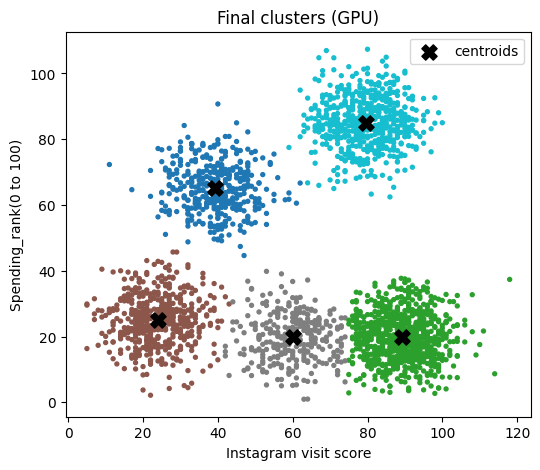

In [ ]:
# Scatter plot of the final GPU clusters with the centroids marked.
raw = pd.read_csv("data.csv")
X = raw.iloc[:, 1:].to_numpy()                   # first column is the User ID, as in the C++ loader
assert len(X) == len(a), "assignments and data must have the same number of rows"
if X.shape[1] >= 2:
    plt.figure(figsize=(6, 5))
    plt.scatter(X[:, 0], X[:, 1], c=a, s=8, cmap="tab10")
    plt.scatter(C[:, 0], C[:, 1], c="black", marker="X", s=120, label="centroids")
    plt.xlabel(raw.columns[1]); plt.ylabel(raw.columns[2]); plt.legend(); plt.title("Final clusters (GPU)")
    plt.show()